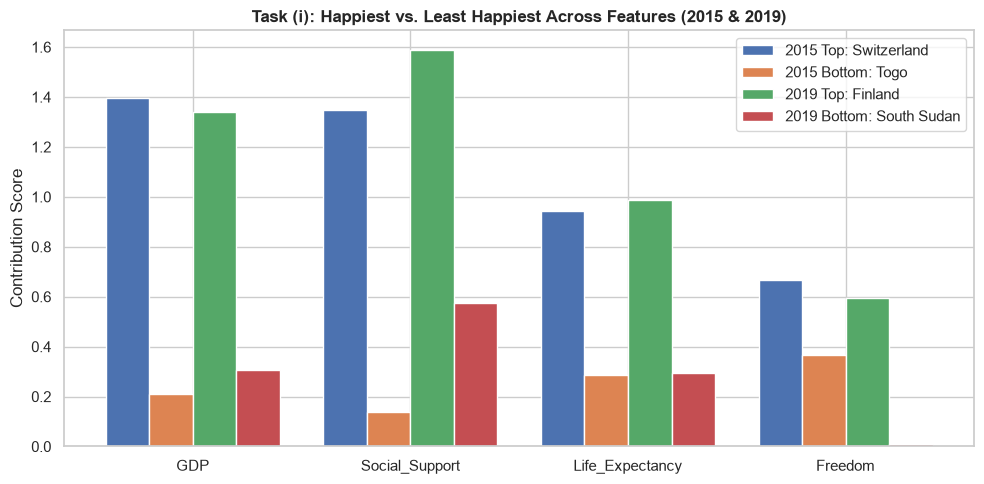


--- Task (ii): Region Happiness Ranking (5-Year Average) ---
                                  mean  median
Region                                        
Australia and New Zealand        7.295   7.296
North America                    7.175   7.198
Western Europe                   6.759   6.940
Latin America and Caribbean      6.021   6.123
Eastern Asia                     5.630   5.655
Central and Eastern Europe       5.429   5.502
Middle East and Northern Africa  5.337   5.274
Southeastern Asia                5.335   5.271
Southern Asia                    4.581   4.565
Sub-Saharan Africa               4.188   4.201


/var/folders/sn/zg9phqwn4llgfxncqcttfsx40000gn/T/ipykernel_8077/4259921630.py:80: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_all, x='Score', y='Region', estimator=np.mean, errorbar=None, palette='viridis')


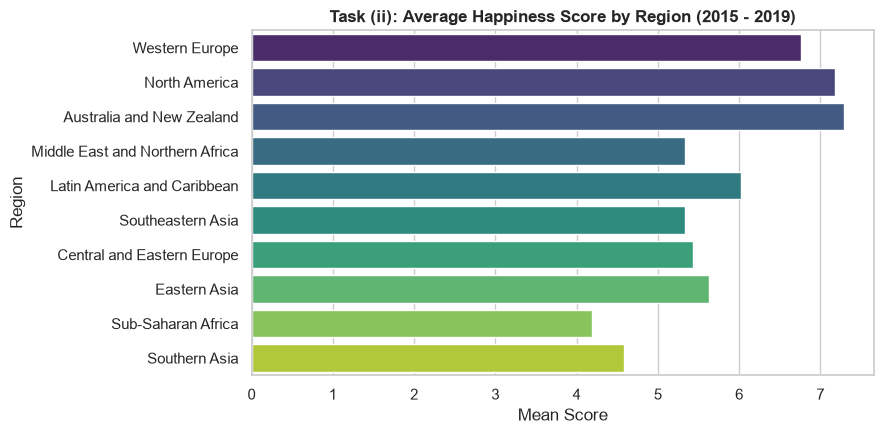


--- Task (iii): Regional Breakdown of Top 10 Countries by Year ---
Region  Australia and New Zealand  North America  Western Europe
Year                                                            
2015                            2              1               7
2016                            2              1               7
2017                            2              1               7
2018                            2              1               7
2019                            1              1               8


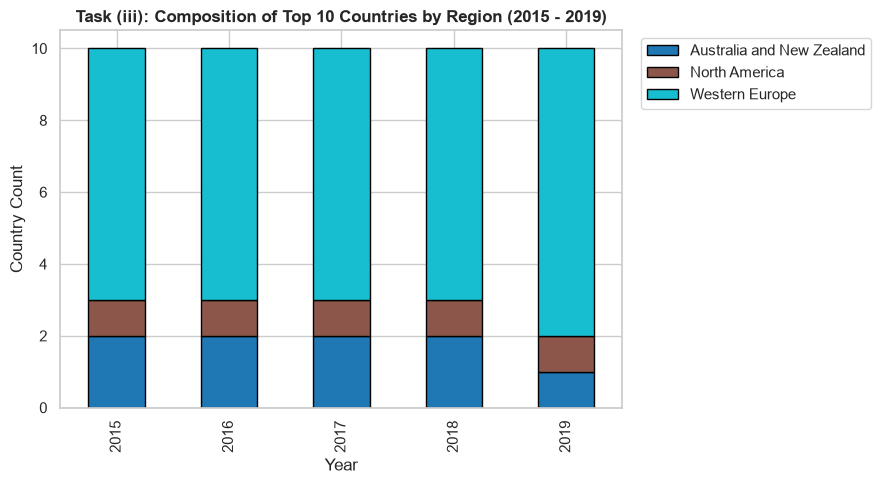


--- Task (iv): Happiest in Latin America & Caribbean Each Year ---
 Year    Country  Score  Rank
 2015 Costa Rica  7.226    12
 2016 Costa Rica  7.087    14
 2017 Costa Rica  7.079    12
 2018 Costa Rica  7.072    13
 2019 Costa Rica  7.167    12

Overall Happiest in LAC (5-Year Mean): Costa Rica (7.126)


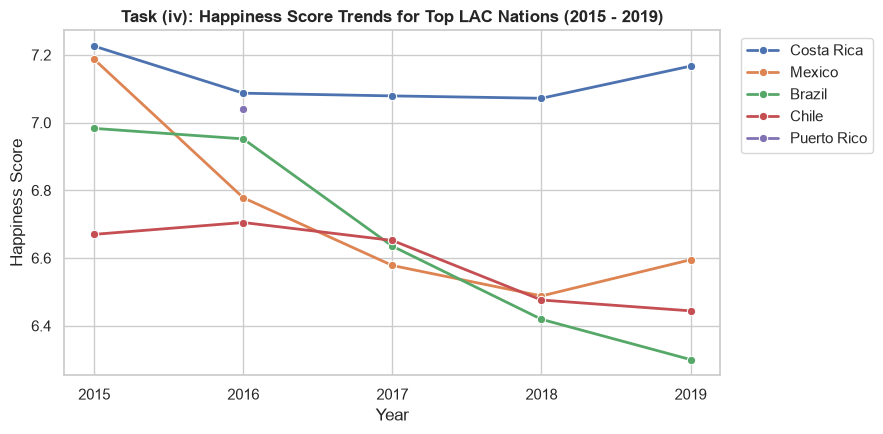

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set overall plot styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

raw_files = {2015: "2015.csv", 2016: "2016.csv", 2017: "2017.csv", 2018: "2018.csv", 2019: "2019.csv"}
dfs = {year: pd.read_csv(path) for year, path in raw_files.items()}

# Region mapping from 2015/2016 to populate missing regions in 2017-2019
region_map = (
    pd.concat([dfs[2015][['Country', 'Region']], dfs[2016][['Country', 'Region']]])
    .drop_duplicates('Country')
    .set_index('Country')['Region']
    .to_dict()
)

# Standardize columns across all 5 schemas (including 2017's dot-notation)
column_aliases = {
    'Country or region': 'Country',
    'Happiness Rank': 'Rank', 'Happiness.Rank': 'Rank', 'Overall rank': 'Rank',
    'Happiness Score': 'Score', 'Happiness.Score': 'Score',
    'Economy (GDP per Capita)': 'GDP', 'Economy..GDP.per.Capita.': 'GDP', 'GDP per capita': 'GDP',
    'Health (Life Expectancy)': 'Life_Expectancy', 'Health..Life.Expectancy.': 'Life_Expectancy', 'Healthy life expectancy': 'Life_Expectancy',
    'Freedom': 'Freedom', 'Freedom to make life choices': 'Freedom',
    'Family': 'Social_Support', 'Social support': 'Social_Support'
}

clean_dfs = []
for year, df in dfs.items():
    d = df.rename(columns=column_aliases).copy()
    d['Year'] = year
    d['Region'] = d['Country'].map(region_map)
    clean_dfs.append(d[['Country', 'Region', 'Rank', 'Score', 'GDP', 'Social_Support', 'Life_Expectancy', 'Freedom', 'Year']])

df_all = pd.concat(clean_dfs, ignore_index=True)


d15 = df_all[df_all['Year'] == 2015].sort_values('Score')
d19 = df_all[df_all['Year'] == 2019].sort_values('Score')

extremes = pd.DataFrame([
    {**d15.iloc[-1][['GDP', 'Social_Support', 'Life_Expectancy', 'Freedom']].to_dict(), 'Label': f"2015 Top: {d15.iloc[-1]['Country']}"},
    {**d15.iloc[0][['GDP', 'Social_Support', 'Life_Expectancy', 'Freedom']].to_dict(), 'Label': f"2015 Bottom: {d15.iloc[0]['Country']}"},
    {**d19.iloc[-1][['GDP', 'Social_Support', 'Life_Expectancy', 'Freedom']].to_dict(), 'Label': f"2019 Top: {d19.iloc[-1]['Country']}"},
    {**d19.iloc[0][['GDP', 'Social_Support', 'Life_Expectancy', 'Freedom']].to_dict(), 'Label': f"2019 Bottom: {d19.iloc[0]['Country']}"}
]).set_index('Label')

# Multi-bar plot using NumPy indices
metrics = extremes.columns
x = np.arange(len(metrics))
bar_width = 0.2

fig, ax = plt.subplots(figsize=(10, 5))
for i, label in enumerate(extremes.index):
    ax.bar(x + (i * bar_width), extremes.loc[label], width=bar_width, label=label)

ax.set_xticks(x + bar_width * 1.5)
ax.set_xticklabels(metrics)
ax.set_title("Task (i): Happiest vs. Least Happiest Across Features (2015 & 2019)", weight='bold')
ax.set_ylabel("Contribution Score")
ax.legend()
plt.tight_layout()
plt.show()


region_summary = (
    df_all.groupby('Region')['Score']
    .agg(['mean', 'median', 'count'])
    .sort_values(by='mean', ascending=False)
)

print("\n--- Task (ii): Region Happiness Ranking (5-Year Average) ---")
print(region_summary[['mean', 'median']].round(3))

plt.figure(figsize=(9, 4.5))
sns.barplot(data=df_all, x='Score', y='Region', estimator=np.mean, errorbar=None, palette='viridis')
plt.title("Task (ii): Average Happiness Score by Region (2015 - 2019)", weight='bold')
plt.xlabel("Mean Score")
plt.tight_layout()
plt.show()

top10_composition = (
    df_all[df_all['Rank'] <= 10]
    .groupby(['Year', 'Region'])
    .size()
    .unstack(fill_value=0)
)

print("\n--- Task (iii): Regional Breakdown of Top 10 Countries by Year ---")
print(top10_composition)

top10_composition.plot(kind='bar', stacked=True, colormap='tab10', figsize=(9, 5), edgecolor='black')
plt.title("Task (iii): Composition of Top 10 Countries by Region (2015 - 2019)", weight='bold')
plt.ylabel("Country Count")
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


lac_data = df_all[df_all['Region'] == 'Latin America and Caribbean']

# Best per year
lac_yearly_top = (
    lac_data.sort_values(['Year', 'Score'], ascending=[True, False])
    .groupby('Year')
    .first()
    .reset_index()[['Year', 'Country', 'Score', 'Rank']]
)

# Best overall (5-year mean)
lac_overall = lac_data.groupby('Country')['Score'].mean().sort_values(ascending=False)

print("\n--- Task (iv): Happiest in Latin America & Caribbean Each Year ---")
print(lac_yearly_top.to_string(index=False))
print(f"\nOverall Happiest in LAC (5-Year Mean): {lac_overall.index[0]} ({lac_overall.iloc[0]:.3f})")

# Trend plot of top 5 contenders in Latin America
top_lac_nations = lac_overall.head(5).index
plt.figure(figsize=(9, 4.5))
sns.lineplot(
    data=lac_data[lac_data['Country'].isin(top_lac_nations)],
    x='Year', y='Score', hue='Country', marker='o', linewidth=2
)
plt.title("Task (iv): Happiness Score Trends for Top LAC Nations (2015 - 2019)", weight='bold')
plt.xticks([2015, 2016, 2017, 2018, 2019])
plt.ylabel("Happiness Score")
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()